# L7 - Go faster: numba and multiprocessing

In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

import numpy as np
import matplotlib.pyplot as plt
import random

## Q1: The stock market

(This is about numba)

A Markov Chain is defined as a sequence of random variables where a parameter depends *only* on the preceding value. This is a crucial tool in statistics, widely used in science and beyond (economics for instance).

For instance, the stock market has phases of growing prices (bull), dreasing prices (bear) and recession. This would be a Markov Chain model:

![](https://upload.wikimedia.org/wikipedia/commons/thumb/9/95/Finance_Markov_chain_example_state_space.svg/400px-Finance_Markov_chain_example_state_space.svg.png)

where the numbers on the arrows indicate the probability that the next day will be in a given state.

Your task is to simulate the stock market according to this rule. Start from a random state and simulate many many  iterations. If your code is right, the fraction of days in each state should converge. 

Implement a pure-python version and a numba version, and compare speeds. 


In [2]:
# I create the matrix with the probabilities provided in the figure

# matrix 3x3 with columns and lines in order: bull (0), bear (1), stagnant (2)
M = np.array([[0.900, 0.075, 0.025],
              [0.150, 0.800, 0.050],
              [0.250, 0.250, 0.500]])

In [3]:
#Python version

def python_market(days, M):
    counts = np.zeros(3) # here I sign the days in each state 
    state = int(3*random.random()) # initial random state

    for day in range(days):
        u = random.random() # random between 0 and 1
        if u < M[state, 0]: # inside bull probability, first column
            state = 0
        elif u < M[state, 0] + M[state, 1]: # inside bear probability
            state = 1
        else:
            state = 2 # by exclusion, is in stagnant probability

        counts[state] += 1

    return counts/days



test = python_market(1000000, M)
print("python:", test)

python: [0.625665 0.311951 0.062384]


In [4]:
#Numba version
from numba import njit

numba_market = njit(python_market)

days = 1000000
print("python:", python_market(days, M))
print("numba :", numba_market(days, M))

python: [0.625716 0.311467 0.062817]
numba : [0.625377 0.311861 0.062762]


In [5]:
%timeit python_market(days, M)

345 ms ± 7.59 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [6]:
%timeit numba_market(days, M)

10.5 ms ± 39.8 µs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [7]:
for n in [1000, 100000, 10000000, 100000000]:
    print(n, " days for bull: ", numba_market(n, M)[0], " bear: ", numba_market(n, M)[1], " stagnant: ", numba_market(n, M)[2])

1000  days for bull:  0.604  bear:  0.361  stagnant:  0.055
100000  days for bull:  0.62262  bear:  0.30905  stagnant:  0.06165
10000000  days for bull:  0.6253658  bear:  0.3126705  stagnant:  0.062313
100000000  days for bull:  0.6250488  bear:  0.3125313  stagnant:  0.06248539


## Q3: Scaling

(This is about multiprocessing)

The ["scaling"](https://hpc-wiki.info/hpc/Scaling) of a code refers to its performance of as a function of the number of cores adopted. 

- Define a computationally intensive task (something like an operation on two giant arrays with >1e7 numbers or, even better!, pick somethinbg from your research). 
- Make sure it's embarrassingly parallel. 
- Implement a parallelization strategy using multiprocessing. 
- Plot the time the code takes as a function of the number of cores.
- Figure out the number of cores in your CPU and make sure the plot extends both below and above this number.
- Interpret the resulting features. 
- A perfect scaling results in straight line (linear dependency). How perfect is your scaling?

In [8]:
import multiprocessing, pathos.multiprocessing
import time
from tqdm.notebook import tqdm

multiprocessing.cpu_count()

# my laptop has 12 cores, but 6 CPUs and 2 threads per CPU, so I can use max 6 cores in parallel 

12

In [9]:
import sys, pickle
sys.path.insert(0, "pta_research") # folder where there are all files needed to run a pulsar timing array (PTA) analysis

from defiant.extra import mdc1_utils
from enterprise_extensions.sampler import setup_sampler #I use PTMCMC sampler

with open("pta_research/psrs.pkl", "rb") as f: #100 simulated pulsars that I use to extract GWB information
    psrs_all = pickle.load(f)



Optional mpi4py package is not installed.  MPI support is not available.


In this exercise I don't do exactly what I would like to do in a real PTA analyis because here I run the code in my laptop (the full run works only in a cluster with more memory), so I had to reduce the number of iterations of the sampler (400 and not 1e6) and the number of pulsars to use for generate each chain (5 for chain and not 100).


In [10]:
def run_chain(i, n_iter=400):

    psrs = psrs_all[5*i : 5*i + 5] # for each chain I take only 5 pulsars

    # Here I model the PTA providing the pulsars and modeling the GWB as a power law, and other settings
    pta = mdc1_utils.build_pta(psrs, gwb_psd='powerlaw', gamma_val=None, gwb_components=30,
                               gwb_name='gw', equadd=-6.0, orf='crn')

    outdir = "ptmcmc_chains/chain_{}".format(i)
    sampler = setup_sampler(pta, outdir, resume=False, human='KAG')

    # random starting point from the prior to initialize the sampler 
    x0 = np.hstack([p.sample() for p in pta.params])
    while not np.isfinite(pta.get_lnlikelihood(x0)):
        x0 = np.hstack([p.sample() for p in pta.params])

    sampler.sample(x0, Niter=n_iter) # run the sampler

    chain = np.loadtxt(outdir + "/chain_1.txt")[:, :2]   # output of the run, columns 0 and 1 are gamma and amplitude posterior distribution
    return chain

In [11]:
cores = [1, 2, 4, 6, 8, 10, 15, 20] # I test here different cores, above and below 6 which is the core number of my laptop
times = []

for core in cores:
    parmap = pathos.multiprocessing.ProcessingPool(core).imap

    t0 = time.time()
    chains = list(parmap(run_chain, range(20))) # I try to generate 20 chains in parallel
    t1 = time.time()

    times.append(t1 - t0)
    print(core, "core:", round(t1 - t0, 2), "s")

tspan:  948327252.2935195
Adding GWB uniform distribution draws...

Finished 100.00 percent in 0.252587 s Acceptance rate = 0.31
Run Complete
tspan:  947914572.8820753
Adding GWB uniform distribution draws...

Finished 0.00 percent in 0.000524 s Acceptance rate = 0

/home/bmoreschi/Desktop/projects/repo/scientificcomputing_bicocca_2025/working/pta_research/enterprise/signals/parameter.py:70: RuntimeWarning: divide by zero encountered in log
  logpdf = np.log(self.prior(value, **kwargs))


Finished 100.00 percent in 0.250125 s Acceptance rate = 0.3525
Run Complete
tspan:  947457247.5104556
Adding GWB uniform distribution draws...

Finished 100.00 percent in 0.255372 s Acceptance rate = 0.34
Run Complete
tspan:  948388058.0600743
Adding GWB uniform distribution draws...

Finished 100.00 percent in 0.280736 s Acceptance rate = 0.3275
Run Complete
tspan:  947269615.0890026
Adding GWB uniform distribution draws...

Finished 100.00 percent in 0.301616 s Acceptance rate = 0.27
Run Complete
tspan:  948114664.0322399
Adding GWB uniform distribution draws...

Finished 100.00 percent in 0.252514 s Acceptance rate = 0.3025
Run Complete
tspan:  947788084.3155012
Adding GWB uniform distribution draws...

Finished 100.00 percent in 0.255800 s Acceptance rate = 0.2825
Run Complete
tspan:  947994250.6159372
Adding GWB uniform distribution draws...

Finished 100.00 percent in 0.253316 s Acceptance rate = 0.31
Run Complete
tspan:  947716108.9325485
Adding GWB uniform distribution draws...

/home/bmoreschi/Desktop/projects/repo/scientificcomputing_bicocca_2025/working/pta_research/enterprise/signals/parameter.py:70: RuntimeWarning: divide by zero encountered in log
  logpdf = np.log(self.prior(value, **kwargs))


Finished 100.00 percent in 0.259474 s Acceptance rate = 0.3525
Run Complete
tspan:  947269615.0890026
Adding GWB uniform distribution draws...

Finished 100.00 percent in 0.278137 s Acceptance rate = 0.29
Run Complete
tspan:  948114664.0322399
Finished 0.00 percent in 0.000830 s Acceptance rate = 0Adding GWB uniform distribution draws...

Finished 100.00 percent in 0.270140 s Acceptance rate = 0.3
Run Complete
tspan:  947788084.3155012
Adding GWB uniform distribution draws...

Finished 0.00 percent in 0.000584 s Acceptance rate = 0

...

Finished 100.00 percent in 0.557925 s Acceptance rate = 0.2925

/home/bmoreschi/Desktop/projects/repo/scientificcomputing_bicocca_2025/working/pta_research/enterprise/signals/parameter.py:70: RuntimeWarning: divide by zero encountered in log
  logpdf = np.log(self.prior(value, **kwargs))



Run Complete


/home/bmoreschi/Desktop/projects/repo/scientificcomputing_bicocca_2025/working/pta_research/enterprise/signals/parameter.py:70: RuntimeWarning: divide by zero encountered in log
  logpdf = np.log(self.prior(value, **kwargs))


Finished 100.00 percent in 0.660301 s Acceptance rate = 0.31
Run Complete
Finished 100.00 percent in 0.723377 s Acceptance rate = 0.355Finished 100.00 percent in 0.705504 s Acceptance rate = 0.3175
Run Complete

Run Complete
Finished 100.00 percent in 0.760044 s Acceptance rate = 0.33Finished 100.00 percent in 0.781430 s Acceptance rate = 0.38
Run Complete
Run Complete

Finished 100.00 percent in 0.801856 s Acceptance rate = 0.3
Run Complete
Finished 100.00 percent in 0.829871 s Acceptance rate = 0.2775
Run Complete
Finished 100.00 percent in 0.862777 s Acceptance rate = 0.2875
Run Complete
Finished 100.00 percent in 0.874714 s Acceptance rate = 0.28
Run Complete
Finished 100.00 percent in 0.914048 s Acceptance rate = 0.2825
Run Complete
Finished 100.00 percent in 0.941757 s Acceptance rate = 0.3525
Run Complete
Finished 100.00 percent in 0.950850 s Acceptance rate = 0.3425
Run Complete
Finished 100.00 percent in 0.965253 s Acceptance rate = 0.3275
Run Complete
Finished 100.00 percent 

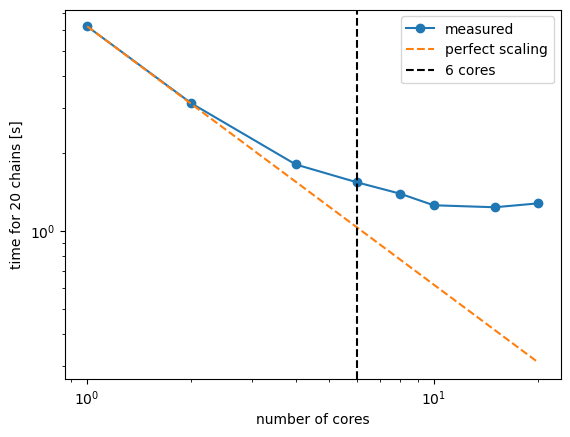

In [12]:
# plot cores vs times
times = np.array(times)
cores = np.array(cores)

fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(cores, times, "o-", label="measured")
ax.plot(cores, times[0]/cores, linestyle="--", label="perfect scaling")

ax.axvline(6, linestyle="--", color="k", label="6 cores")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("number of cores")
ax.set_ylabel("time for 20 chains [s]")
ax.legend()


Looking the plot, the analysis is close to the ideal line using only 2 cores.

The time start to reach a plateau from 6 cores, which makes sense since my laptop don't have more than 6 cores, so if I require more cores, still it will use maximum 6 cores, and the time cannot decrease.